# Diagnostics and Business Insights

**Objective:** Diagnose where the final LightGBM ranking model performs well or poorly on the held-out test set, compare it with the training-user Popularity baseline, and translate the findings into evidence-based business insights.

**NOTE: This notebook only takes into account the LightGBM model. Refer to `Truman_BST_Additional_Diagnostics.ipynb` for the insights on the BST model.**


## How to Use This Notebook

This notebook contains the diagnostics and business insights analysis for the final LightGBM ranking model.

### Execution Instructions

1. Ensure that the project Google Drive folder and `Scoring_Code.ipynb` are accessible.
2. Open the notebook in Google Colab and mount Google Drive when prompted.
3. Run all cells sequentially from top to bottom. The notebook depends on variables and functions defined in earlier sections.
4. If the Colab runtime is disconnected or restarted, rerun the notebook from the beginning.
5. The final diagnostic tables are automatically exported as CSV files to the project Google Drive folder.

### Important Notes

- The analysis uses the existing held-out test split and final LightGBM predictions.
- The model is not retrained or tuned in this notebook.
- The shared scoring implementation is reused to ensure consistency with the evaluation metrics.
- `session_id` is retained as the evaluation identifier.

### Notebook Structure

- **S1–S5:** Diagnostic framework, setup, data loading and segment creation.
- **S6–S9:** Performance comparisons, personalisation benefits, product popularity and historical purchase behaviour.
- **S10–S11:** Visualisations and export of diagnostic results.
- **S12:** Overall findings, feature insights and business implications.
- **S13:** Summary of diagnostic findings and limitations.

> Toggle to the respective sections using the Table of Contents menu.

## S1. Diagnostic Framework

| Diagnostic Area | What We Want To Investigate | Potential Business Insights |
|---|---|---|
| **Product popularity** | Formal cold vs warm product classification <br> Supplementary training-popularity proxy | Can the recommender surface less-established products? |
| **User activity** | Recent vs inactive sessions | Does recent activity improve ranking? |
| **User history length** | Short vs long interaction histories | How much does historical information help? |
| **Search slate size** | Short vs long candidate lists | Does ranking become harder with more candidates? |
| **Personalisation benefit** | LightGBM vs Popularity, by session and segment | Which sessions benefit most from personalisation? |
| **Purchase behaviour** | Prior purchasers vs users without recorded purchases | Which behavioural groups benefit most? |





## S2. Setup and load the shared scoring code

Scoring notebook is loaded with `%run`, so its `evaluate_ranking` and `rank_candidates` functions are reused rather than reimplemented.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE = "/content/drive/MyDrive/BT4222 Final/JDSearch/"
SCORING_NOTEBOOK = "/content/drive/MyDrive/BT4222 Final/Scoring_Code.ipynb"

assert os.path.exists(BASE), f"Check Google Drive path: {BASE}"
assert os.path.exists(SCORING_NOTEBOOK), f"Scoring notebook not found: {SCORING_NOTEBOOK}"

%run "/content/drive/MyDrive/BT4222 Final/Scoring_Code.ipynb"

PRED_PATH = BASE + "model_artifacts/lightgbm_popularity_query_search/full/test_predictions.parquet"
TEST_PATH = BASE + "processed/lgbm_features_all/test.parquet"

assert os.path.exists(PRED_PATH), f"Missing LightGBM predictions: {PRED_PATH}"
assert os.path.exists(TEST_PATH), f"Missing processed test data: {TEST_PATH}"

print("Scoring functions loaded.")


Mounted at /content/drive
NDCG@10     : 0.635 (expect 0.635)
MRR         : 0.5 (expect 0.5)
P@1         : 0.0 (expect 0.0)
EngRecall@2 : 0.5 (expect 0.5)
PurRecall@2 : 1.0 (expect 1.0)
PurRecall when the user bought nothing: None (expect None, user left out of the average)
NDCG@10 if ties keep the stored order : 0.941 (fake, far too high)
NDCG@10 with random tie-breaking      : 0.076 (random level)
Perfect: {'NDCG@10': 1.0, 'MRR': 1.0, 'P@1': 1.0, 'EngRecall@10': 1.0, 'PurRecall@10': 1.0, 'EngRecall@10 cold': 1.0, 'EngRecall@10 warm': 1.0}
Random : {'NDCG@10': 0.082, 'MRR': 0.115, 'P@1': 0.034, 'EngRecall@10': 0.16, 'PurRecall@10': 0.153, 'EngRecall@10 cold': 0.162, 'EngRecall@10 warm': 0.167}
Scoring functions loaded.


## S3. Load predictions and test-set context

We load only the columns needed for the diagnostics. The feature table has one row per candidate product, while the context table is reduced to one row per `session_id`.

The handoff's identifier mapping is retained: `session_id` → `user_id`, `wid` → `item_id`.


In [ ]:
# LightGBM: saved score for every test candidate
lgbm_pred = pd.read_parquet(PRED_PATH)
lgbm_pred = lgbm_pred.rename(columns={"session_id": "user_id", "wid": "item_id"})
lgbm_pred = lgbm_pred[["user_id", "item_id", "label", "score"]].copy()

# Popularity baseline: item_ctr_train is computed from training users only
pop = pd.read_parquet(
    TEST_PATH,
    columns=["session_id", "wid", "label", "item_ctr_train"]
)
pop = pop.rename(columns={
    "session_id": "user_id",
    "wid": "item_id",
    "item_ctr_train": "score"
})
pop = pop[["user_id", "item_id", "label", "score"]].copy()

# One row of session-level context per session
context_cols = [
    "session_id", "history_len_clean",
    "days_since_last_interaction", "slate_size",
    "click_count_0_7d", "cart_count_0_7d", "ord_count_0_7d",
    "flw_count_0_7d", "click_count_7_90d", "cart_count_7_90d",
    "ord_count_7_90d", "flw_count_7_90d",
    "click_count_90_365d", "cart_count_90_365d",
    "ord_count_90_365d", "flw_count_90_365d"
]
test_features = pd.read_parquet(TEST_PATH, columns=context_cols)
ctx = test_features.drop_duplicates("session_id").rename(columns={"session_id": "user_id"}).copy()

print("LightGBM prediction rows:", len(lgbm_pred))
print("Popularity prediction rows:", len(pop))
print("Test sessions:", ctx["user_id"].nunique())
print("Candidate sessions in LightGBM:", lgbm_pred["user_id"].nunique())

assert not lgbm_pred.duplicated(["user_id", "item_id"]).any(), "Duplicate LightGBM user-item rows."
assert set(lgbm_pred["user_id"].unique()) == set(pop["user_id"].unique()), "Session sets differ."
assert len(lgbm_pred) == len(pop), "Candidate row counts differ; investigate before comparing."

# Verify that both models contain exactly the same candidate pairs
pair_check = lgbm_pred[
    ["user_id", "item_id", "label"]
].merge(
    pop[["user_id", "item_id", "label"]],
    on=["user_id", "item_id"],
    how="outer",
    suffixes=("_lgbm", "_pop"),
    indicator=True,
    validate="one_to_one"
)

assert pair_check["_merge"].eq("both").all(), \
    "LightGBM and Popularity contain different candidate pairs."

assert (
    pair_check["label_lgbm"] == pair_check["label_pop"]
).all(), "Labels differ between the two prediction sets."

print("Candidate pairs and labels match.")


LightGBM prediction rows: 1531525
Popularity prediction rows: 1531525
Test sessions: 17118
Candidate sessions in LightGBM: 17118
Candidate pairs and labels match.


## S4. Reproduce the overall test metrics and calculate per-session metrics

This is the diagnostic baseline. The overall results should be close to Elysia's reported test results. Investigate any material discrepancy before proceeding.


In [ ]:
lgbm_metrics, lgbm_user = evaluate_ranking(lgbm_pred, per_user=True)
pop_metrics, pop_user = evaluate_ranking(pop, per_user=True)

overall = pd.DataFrame([
    {"Model": "LightGBM", **lgbm_metrics},
    {"Model": "Popularity", **pop_metrics}
]).set_index("Model")

display(overall.round(4))

# Keep per-session metrics side by side.
lgbm_user = lgbm_user.add_prefix("lgbm_").rename(columns={"lgbm_user_id": "user_id"})
pop_user = pop_user.add_prefix("pop_").rename(columns={"pop_user_id": "user_id"})

per_session = lgbm_user.merge(pop_user, on="user_id", how="inner", validate="one_to_one")
per_session = per_session.merge(ctx, on="user_id", how="left", validate="one_to_one")

print("Per-session diagnostic table:", per_session.shape)
print("Sessions with missing history length:", per_session["history_len_clean"].isna().sum())
print("Sessions with missing recency:", per_session["days_since_last_interaction"].isna().sum())


Scored 17,118 users (1,988 with a purchase)
NOTE: many tied scores. Ties are broken randomly (see top of file).
Scored 17,118 users (1,988 with a purchase)


,NDCG@10,MRR,P@1,EngRecall@5,PurRecall@5,EngRecall@10,PurRecall@10,EngRecall@20,PurRecall@20,n_users,n_users_with_purchase
Model,,,,,,,,,,,
LightGBM,0.4054,0.4122,0.2718,0.4512,0.4921,0.5890,0.6412,0.7272,0.7808,17118,1988
Popularity,0.2549,0.2677,0.1577,0.2889,0.2984,0.3853,0.4018,0.4758,0.4819,17118,1988


Per-session diagnostic table: (17118, 36)
Sessions with missing history length: 0
Sessions with missing recency: 0


**Interpretation**

LightGBM consistently outperforms the popularity-based baseline across all evaluated ranking metrics. Its NDCG@10 of 0.4054 is substantially higher than the baseline's 0.2549, indicating that it is more effective at placing relevant products towards the top of the recommendation list.

The improvement is also reflected in Purchase Recall@10, which increases from 0.4018 to 0.6412. This suggests that LightGBM is better at retrieving products that users are likely to purchase, rather than simply prioritising products with historically high popularity.

**Business insight**

Incorporating user-specific interaction history and product-related features provides value beyond popularity-based ranking, potentially enabling more relevant and commercially useful product recommendations.

## S5. Create diagnostic segments

Use the suggested history-length thresholds from Elysia's handoff: fewer than 3 actions, 3–20 actions, and more than 20 actions.

For recency, use interpretable time bands. Missing recency is kept as its own category rather than silently treated as zero. Slate size is split into three approximately equal-sized groups using test-set quantiles; the cut points are printed for transparency.


In [ ]:
per_session["history_group"] = np.select(
    [
        per_session["history_len_clean"] < 3,
        per_session["history_len_clean"].between(
            3, 20, inclusive="both"
        ),
        per_session["history_len_clean"] > 20
    ],
    [
        "Short (<3)",
        "Medium (3–20)",
        "Long (>20)"
    ],
    default="Missing"
)

# Recency: days since last interaction
recency_bins = [-np.inf, 7, 30, 90, np.inf]
recency_labels = ["Recent (≤7d)", "8–30d", "31–90d", "Older (>90d)"]
per_session["recency_group"] = pd.cut(
    per_session["days_since_last_interaction"],
    bins=recency_bins,
    labels=recency_labels,
    right=True
).astype("object")
per_session.loc[
    per_session["days_since_last_interaction"].isna(),
    "recency_group"
] = "No recorded recency"

# Slate size: approximate tertiles. Duplicated cut points are handled.
slate_codes, slate_edges = pd.qcut(
    per_session["slate_size"], q=3, labels=False,
    retbins=True, duplicates="drop"
)
slate_labels = {0: "Small slate", 1: "Medium slate", 2: "Large slate"}
per_session["slate_group"] = slate_codes.map(slate_labels)
print("Slate-size quantile boundaries:", slate_edges)
print("\nSegment counts:")
for col in ["history_group", "recency_group", "slate_group"]:
    print("\n", col)
    display(per_session[col].value_counts(dropna=False).rename("sessions").to_frame())


Slate-size quantile boundaries: [  2.  87.  92. 200.]

Segment counts:

 history_group


,sessions
history_group,
Long (>20),13890
Medium (3–20),2838
Short (<3),390



 recency_group


,sessions
recency_group,
Recent (≤7d),15167
8–30d,1292
31–90d,515
Older (>90d),144



 slate_group


,sessions
slate_group,
Medium slate,6278
Small slate,5761
Large slate,5079


## S6. Compare LightGBM and Popularity across user/session groups

For each segment, report:
- number of sessions;
- LightGBM and Popularity NDCG@10;
- absolute NDCG@10 improvement;
- LightGBM and Popularity Engagement Recall@10;
- absolute Engagement Recall@10 improvement.

The difference is calculated as **LightGBM − Popularity**. Positive values indicate that LightGBM performs better on that metric within the segment.

Recall metrics are macro-averaged over sessions for which the metric is defined, matching the shared scoring implementation.


In [ ]:
def segment_comparison(data, group_col):
    rows = []
    for group, g in data.groupby(group_col, observed=False, dropna=False):
        if len(g) == 0:
            continue
        row = {
            "Segment": str(group),
            "Sessions": g["user_id"].nunique(),
            "LGBM NDCG@10": g["lgbm_NDCG@10"].mean(),
            "Popularity NDCG@10": g["pop_NDCG@10"].mean(),
            "NDCG@10 Δ": g["lgbm_NDCG@10"].mean() - g["pop_NDCG@10"].mean(),
            "LGBM EngRecall@10": g["lgbm_EngRecall@10"].mean(),
            "Popularity EngRecall@10": g["pop_EngRecall@10"].mean(),
            "EngRecall@10 Δ": g["lgbm_EngRecall@10"].mean() - g["pop_EngRecall@10"].mean()
        }
        rows.append(row)
    return pd.DataFrame(rows)

history_results = segment_comparison(per_session, "history_group")
recency_results = segment_comparison(per_session, "recency_group")
slate_results = segment_comparison(per_session, "slate_group")

print("Performance by history length")
display(history_results.round(4))

print("Performance by recency")
display(recency_results.round(4))

print("Performance by slate size")
display(slate_results.round(4))


Performance by history length


,Segment,Sessions,LGBM NDCG@10,Popularity NDCG@10,NDCG@10 Δ,LGBM EngRecall@10,Popularity EngRecall@10,EngRecall@10 Δ
0,Long (>20),13890,0.4083,0.2532,0.1551,0.5938,0.3837,0.2101
1,Medium (3–20),2838,0.3948,0.2619,0.1329,0.5687,0.3929,0.1758
2,Short (<3),390,0.3812,0.2637,0.1175,0.5687,0.3889,0.1798


Performance by recency


,Segment,Sessions,LGBM NDCG@10,Popularity NDCG@10,NDCG@10 Δ,LGBM EngRecall@10,Popularity EngRecall@10,EngRecall@10 Δ
0,31–90d,515,0.3633,0.2646,0.0987,0.5662,0.4095,0.1567
1,8–30d,1292,0.3709,0.2557,0.1152,0.5667,0.3922,0.1745
2,Older (>90d),144,0.3673,0.2590,0.1083,0.5611,0.4036,0.1575
3,Recent (≤7d),15167,0.4102,0.2545,0.1557,0.5920,0.3838,0.2082


Performance by slate size


,Segment,Sessions,LGBM NDCG@10,Popularity NDCG@10,NDCG@10 Δ,LGBM EngRecall@10,Popularity EngRecall@10,EngRecall@10 Δ
0,Large slate,5079,0.2582,0.1606,0.0976,0.3630,0.2345,0.1285
1,Medium slate,6278,0.4541,0.2934,0.1607,0.6758,0.4466,0.2292
2,Small slate,5761,0.4823,0.2962,0.1861,0.6938,0.4515,0.2423


<u> **User History Length** </u>

**Interpretation**

LightGBM outperforms the Popularity baseline across all three history-length groups. However, the improvement is greatest among sessions with longer interaction histories.

Sessions with long histories achieve the highest NDCG@10 improvement (+0.1551), followed by medium-history (+0.1329) and short-history sessions (+0.1175). This suggests that LightGBM benefits from having access to richer historical interaction data when personalising product rankings.

Nevertheless, even sessions with fewer than three historical interactions benefit from LightGBM, indicating that the model can still provide value when relatively little user history is available.

**Business Insight**

Maintaining and leveraging historical interaction data can improve personalised product recommendations. However, the model should also retain effective fallback signals for users with limited interaction histories.

<u> **User Activity Recency** </u>

**Interpretation**

Recently active sessions achieve the highest NDCG and the largest improvement over the popularity baseline. LightGBM's NDCG improvement is +0.1557 for recently active sessions, compared with smaller improvements across the less-recent groups. This suggests that recent interactions provide useful signals about users' current interests.

The pattern is not perfectly monotonic: the oldest group performs slightly better than the 31–90-day group, although it contains only 144 sessions.

**Business Insight**

Because recent interaction signals appear useful for personalisation, platforms could consider refreshing or prioritising recent behavioural signals when generating recommendations.

<u> **Candidate Slate Size** </u>

**Interpretation**

Both models perform less effectively on larger candidate slates, but LightGBM consistently outperforms Popularity.

LightGBM's improvement decreases as candidate slate size increases, as seen by the decrease in NDCG@10 Δ from +0.1861 for small slate to +0.1607 for medium slate to +0.0976 for large slate.

Although LightGBM continues to outperform the baseline, its advantage is smaller for large slates. This suggests that ranking becomes more challenging when the model has to distinguish relevant products from a larger candidate pool.

> Slate-size groups were formed using quantile boundaries of approximately 2, 87, 92 and 200 candidates. These are data-driven groups rather than fixed business thresholds.

**Business Insight**

Because ranking becomes more challenging when users are presented with more candidate products, improving candidate retrieval or filtering before ranking could help reduce the difficulty of selecting relevant products from larger slates.

## S7. Personalisation benefit at the individual-session level

Calculate the difference in NDCG@10 and Engagement Recall@10 between LightGBM and Popularity for every session. Then summarise those differences by history length and recency.

A positive difference means LightGBM improved over the popularity baseline for that session. A negative difference means Popularity did better. This directly addresses: **which kinds of users benefit most from personalisation?**


In [ ]:
per_session["NDCG_gain_vs_popularity"] = (
    per_session["lgbm_NDCG@10"] - per_session["pop_NDCG@10"]
)
per_session["EngRecall_gain_vs_popularity"] = (
    per_session["lgbm_EngRecall@10"] - per_session["pop_EngRecall@10"]
)

benefit_by_history = per_session.groupby("history_group", observed=False).agg(
    Sessions=("user_id", "nunique"),
    Mean_NDCG_gain=("NDCG_gain_vs_popularity", "mean"),
    Median_NDCG_gain=("NDCG_gain_vs_popularity", "median"),
    Share_sessions_LGBM_better=("NDCG_gain_vs_popularity", lambda x: (x > 0).mean()),
    Mean_EngRecall_gain=("EngRecall_gain_vs_popularity", "mean")
).reset_index()

benefit_by_recency = per_session.groupby("recency_group", observed=False).agg(
    Sessions=("user_id", "nunique"),
    Mean_NDCG_gain=("NDCG_gain_vs_popularity", "mean"),
    Median_NDCG_gain=("NDCG_gain_vs_popularity", "median"),
    Share_sessions_LGBM_better=("NDCG_gain_vs_popularity", lambda x: (x > 0).mean()),
    Mean_EngRecall_gain=("EngRecall_gain_vs_popularity", "mean")
).reset_index()

print("Personalisation benefit by history length")
display(benefit_by_history.round(4))
print("Personalisation benefit by recency")
display(benefit_by_recency.round(4))


Personalisation benefit by history length


,history_group,Sessions,Mean_NDCG_gain,Median_NDCG_gain,Share_sessions_LGBM_better,Mean_EngRecall_gain
0,Long (>20),13890,0.1551,0.0,0.4812,0.2101
1,Medium (3–20),2838,0.1329,0.0,0.4352,0.1758
2,Short (<3),390,0.1175,0.0,0.4231,0.1798


Personalisation benefit by recency


,recency_group,Sessions,Mean_NDCG_gain,Median_NDCG_gain,Share_sessions_LGBM_better,Mean_EngRecall_gain
0,31–90d,515,0.0987,0.0,0.3883,0.1567
1,8–30d,1292,0.1152,0.0,0.4489,0.1745
2,Older (>90d),144,0.1083,0.0,0.4375,0.1575
3,Recent (≤7d),15167,0.1557,0.0,0.4774,0.2082


**Interpretation**

The improvement from LightGBM is not uniform across individual sessions. Although the average NDCG improvement is positive across all history-length groups, the median improvement is zero in every group.

Furthermore, LightGBM achieves a higher NDCG than Popularity in fewer than half of individual sessions across all three groups. The proportion is highest among sessions with longer histories (48.12%), followed by medium-history (43.52%) and short-history sessions (42.31%).

This indicates that the model's overall improvement is real at the aggregate level, but it does not mean every individual session benefits. The positive average improvement, despite fewer than half of sessions recording a positive difference, suggests that the magnitude of improvements in sessions where LightGBM performs better is sufficient to outweigh the losses and ties.

**Business Insight**

While personalised ranking improves aggregate performance, businesses should also investigate sessions where personalisation provides little or no benefit. This could help identify opportunities to improve recommendation quality for less-responsive user segments.

## S8. Product popularity and cold/warm product diagnostics

The main results already report Engagement Recall@10 separately for **cold** and **warm** products, using Elysia's formal definition: cold products never appear in any user's interaction history.

For an additional diagnostic using the processed test table, `item_ctr_train` measures product interaction popularity from training users. We classify candidates with zero training popularity separately from candidates with non-zero popularity. <br>
This is a **training-popularity proxy**, not a replacement for the formal cold/warm definition.

The calculation below asks: <br>
Among all relevant products in each popularity tier for a session, what proportion are found in the model's top 10? <br>
Sessions with no relevant products in a tier are excluded from that tier's recall average.


In [ ]:
# Prepare product popularity diagnostics

item_pop = (
    pop[["user_id", "item_id", "score"]]
    .rename(columns={"score": "item_ctr_train"})
)

lgbm_pop_diag = lgbm_pred.merge(
    item_pop,
    on=["user_id", "item_id"],
    how="left",
    validate="one_to_one"
)

assert lgbm_pop_diag["item_ctr_train"].notna().all()

lgbm_pop_diag["popularity_tier"] = np.where(
    lgbm_pop_diag["item_ctr_train"] <= 0,
    "Zero training popularity",
    "Non-zero training popularity"
)

ranked_pop = rank_candidates(
    lgbm_pop_diag,
    seed=RANDOM_SEED
)

print("Ranked predictions:", ranked_pop.shape)

display(
    lgbm_pop_diag["popularity_tier"]
    .value_counts()
    .rename_axis("Popularity tier")
    .to_frame("Candidate rows")
)

Ranked predictions: (1531525, 7)


,Candidate rows
Popularity tier,
Non-zero training popularity,1531525


In [ ]:
def popularity_tier_recall(ranked, k=10):
    rows = []
    # For each session, compare all relevant candidates in a tier with those
    # from that tier that actually appear in the model's overall top-k list.
    for uid, g in ranked.groupby("user_id", sort=False):
        top_k = g.head(k)
        for tier, tier_all in g.groupby("popularity_tier", sort=False):
            relevant_mask = tier_all["label"].to_numpy() >= 1
            denominator = int(relevant_mask.sum())
            if denominator == 0:
                continue
            hits = int(((top_k["label"] >= 1) &
                        (top_k["popularity_tier"] == tier)).sum())
            rows.append({
                "Popularity tier": tier,
                "user_id": uid,
                "Relevant products in tier": denominator,
                "Tier EngRecall@10": hits / denominator
            })
    per_user_tier = pd.DataFrame(rows)
    summary = per_user_tier.groupby("Popularity tier").agg(
        Sessions=("user_id", "nunique"),
        Mean_EngRecall_at_10=("Tier EngRecall@10", "mean")
    ).reset_index()
    return summary, per_user_tier

popularity_tier_summary, popularity_tier_per_session = popularity_tier_recall(ranked_pop)
display(popularity_tier_summary.round(4))

cold_warm_results = pd.DataFrame([
    {
        "Product Type": "Cold",
        "LightGBM EngRecall@10": 0.1988,
        "Popularity EngRecall@10": 0.1586,
        "Improvement": 0.1988 - 0.1586
    },
    {
        "Product Type": "Warm",
        "LightGBM EngRecall@10": 0.6803,
        "Popularity EngRecall@10": 0.4286,
        "Improvement": 0.6803 - 0.4286
    }
])

display(cold_warm_results.round(4))


,Popularity tier,Sessions,Mean_EngRecall_at_10
0,Non-zero training popularity,17118,0.589


,Product Type,LightGBM EngRecall@10,Popularity EngRecall@10,Improvement
0,Cold,0.1988,0.1586,0.0402
1,Warm,0.6803,0.4286,0.2517


**Interpretation**

LightGBM outperforms the popularity baseline for both cold and warm products, but the improvement is substantially greater for warm products. For cold products, Engagement Recall@10 improves from 0.1586 to 0.1988, while for warm products it increases from 0.4286 to 0.6803.

The improvement for cold products suggests that LightGBM can identify some relevant products even when they have limited historical interaction data. However, recall remains considerably higher for warm products, indicating that products with established interaction histories are still easier to recommend effectively.

> The results are taken from the earlier held-out test evaluation using the formal cold/warm product definition. They are included here as previously reported evaluation results rather than newly calculated results in this notebook.

All 1,531,525 candidate rows have non-zero training popularity, meaning this particular proxy cannot meaningfully separate zero-popularity from non-zero-popularity candidates.

Therefore, the formal cold/warm evaluation is used for this comparison.

**Business Insight**

Personalised ranking can help improve exposure of less-established products, although the gap between cold and warm product performance highlights an opportunity to strengthen recommendations for products with limited interaction histories.

## S9. Past purchase behaviour

The available feature table includes historical order and click counts. We derive a simple historical segment from those counts.

This describes **past recorded behaviour**, not the test labels. It is therefore suitable as a diagnostic grouping variable.


In [ ]:
order_cols = [
    "ord_count_0_7d", "ord_count_7_90d", "ord_count_90_365d"
]
click_cols = [
    "click_count_0_7d", "click_count_7_90d", "click_count_90_365d"
]

per_session["past_orders"] = per_session[order_cols].fillna(0).sum(axis=1)
per_session["past_clicks"] = per_session[click_cols].fillna(0).sum(axis=1)

per_session["past_purchase_group"] = np.select(
    [
        per_session["past_orders"] > 0,
        (per_session["past_orders"] == 0) & (per_session["past_clicks"] > 0)
    ],
    ["Prior purchaser", "Clicks but no recorded purchase"],
    default="No recorded clicks or purchases"
)

purchase_history_results = segment_comparison(per_session, "past_purchase_group")
display(purchase_history_results.round(4))


,Segment,Sessions,LGBM NDCG@10,Popularity NDCG@10,NDCG@10 Δ,LGBM EngRecall@10,Popularity EngRecall@10,EngRecall@10 Δ
0,Clicks but no recorded purchase,1187,0.4471,0.2860,0.1611,0.6250,0.4252,0.1999
1,No recorded clicks or purchases,262,0.3819,0.3059,0.0759,0.5516,0.4111,0.1405
2,Prior purchaser,15669,0.4027,0.2517,0.1510,0.5869,0.3819,0.2051


**Interpretation**

LightGBM outperforms the popularity baseline across all three historical purchase-behaviour groups. The strongest NDCG improvement is among sessions with clicks but no recorded purchases (+0.1611), while sessions with no recorded clicks or purchases have the smallest improvement (+0.0759).

This suggests that the model benefits from having stronger historical interaction signals.

> "No recorded clicks or purchases" does not necessarily mean these sessions have no interaction history whatsoever. Other historical actions, such as follows, may still exist.

**Business Insight**

Personalised ranking may be particularly useful for users who have demonstrated product interest but have not yet converted into purchases. These users could be an important target group for improving engagement and conversion.

## S10. Visualise the key comparisons

These charts are descriptive. Refer to the table outputs above for exact values and sample sizes.


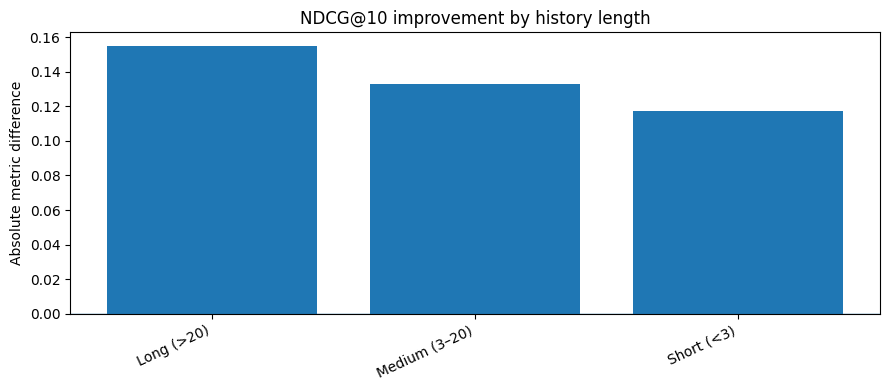

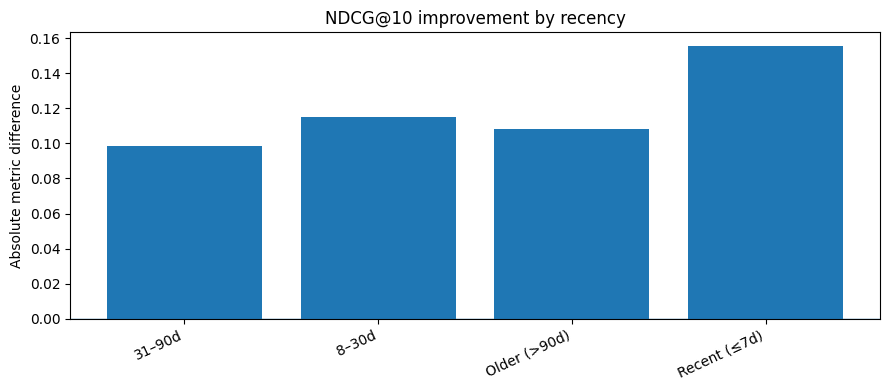

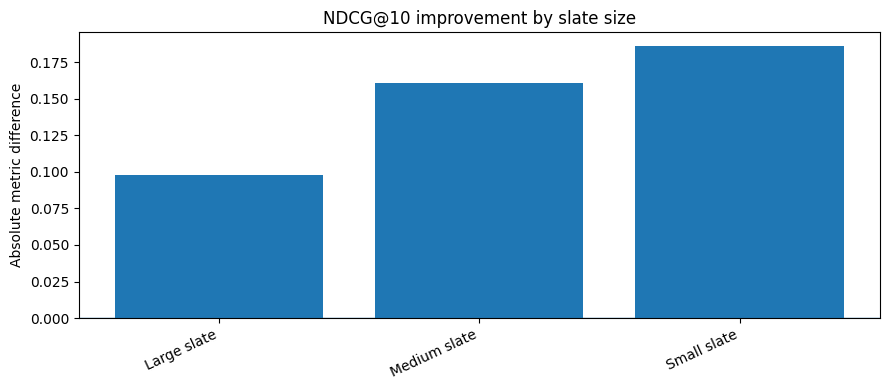

In [ ]:
def plot_delta(table, segment_col="Segment", delta_col="NDCG@10 Δ", title="NDCG@10 improvement: LightGBM − Popularity"):
    if table.empty:
        print("No groups available to plot.")
        return
    plot_df = table.copy()
    plt.figure(figsize=(9, 4))
    plt.bar(plot_df[segment_col].astype(str), plot_df[delta_col])
    plt.axhline(0, linewidth=1)
    plt.ylabel("Absolute metric difference")
    plt.title(title)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

plot_delta(history_results, title="NDCG@10 improvement by history length")
plot_delta(recency_results, title="NDCG@10 improvement by recency")
plot_delta(slate_results, title="NDCG@10 improvement by slate size")


## S11. Export diagnostic tables

These compact CSVs can be used in the report and presentation. They contain aggregated results rather than the full candidate-level data.


In [ ]:
OUT_DIR = BASE + "model_artifacts/Truman_diagnostics/"
os.makedirs(OUT_DIR, exist_ok=True)

history_results.to_csv(OUT_DIR + "diagnostics_by_history_length.csv", index=False)
recency_results.to_csv(OUT_DIR + "diagnostics_by_recency.csv", index=False)
slate_results.to_csv(OUT_DIR + "diagnostics_by_slate_size.csv", index=False)
benefit_by_history.to_csv(OUT_DIR + "personalisation_benefit_by_history.csv", index=False)
benefit_by_recency.to_csv(OUT_DIR + "personalisation_benefit_by_recency.csv", index=False)
popularity_tier_summary.to_csv(OUT_DIR + "supplementary_training_popularity_proxy.csv", index=False)
purchase_history_results.to_csv(OUT_DIR + "diagnostics_by_purchase_history.csv", index=False)
per_session.to_csv(OUT_DIR + "per_session_diagnostics.csv", index=False)

print("Saved diagnostic outputs to:", OUT_DIR)


Saved diagnostic outputs to: /content/drive/MyDrive/BT4222 Final/JDSearch/model_artifacts/Truman_diagnostics/


## S12. Overall Findings and Business Implications

1. **Historical interactions improve recommendation quality.** LightGBM outperforms the Popularity baseline across all history-length groups. Sessions with longer histories demonstrate the greatest average improvement, suggesting that richer historical interaction data can support more effective personalisation.

2. **Recent activity is valuable.** Sessions with activity within the past seven days achieve the strongest improvement over Popularity, highlighting the usefulness of recent behavioural signals.

3. **Larger candidate sets are more challenging.** Both models experience lower ranking performance as slate size increases. Candidate filtering and retrieval improvements could help address this challenge.

4. **Personalisation benefits are not uniform.** Although LightGBM improves aggregate performance, fewer than half of individual sessions record a higher NDCG@10 than Popularity. Further investigation into sessions with limited or no improvement could help identify areas for model enhancement.

5. **Warm products are easier to recommend than cold products.** LightGBM outperforms Popularity for both product types, but engagement recall is considerably higher for warm products. This highlights the continued challenge of recommending products with limited historical interaction data.

6. **Users who show interest but have not purchased may be a valuable segment.** Sessions with clicks but no recorded purchases achieve the largest NDCG@10 improvement among the purchase-history groups, suggesting potential opportunities to improve engagement and conversion strategies.

The diagnostic results demonstrated that LightGBM consistently outperforms the popularity-based baseline across the evaluated ranking metrics and user segments.

The findings are descriptive evaluations on the held-out test set and do not establish causal improvements in actual purchasing behaviour.

> Overall, the findings support the use of personalised ranking over popularity-based ranking, while highlighting opportunities to improve recommendations for less-active users, cold products and sessions with larger candidate sets.

### S12.1. What the Model Learns: Feature Importance and Ablation Evidence

In [ ]:
# Table 1: Feature ablation results

ablation_results = pd.DataFrame([
    {
        "Experiment": "All features (Baseline)",
        "Validation NDCG@10": 0.402,
        "Change from baseline": 0.000
    },
    {
        "Experiment": "Without personal-history features",
        "Validation NDCG@10": 0.331,
        "Change from baseline": -0.071
    },
    {
        "Experiment": "Without popularity priors",
        "Validation NDCG@10": 0.350,
        "Change from baseline": -0.052
    },
    {
        "Experiment": "Without title similarity",
        "Validation NDCG@10": 0.397,
        "Change from baseline": -0.005
    },
    {
        "Experiment": "Without Item2Vec",
        "Validation NDCG@10": 0.399,
        "Change from baseline": -0.003
    },
    {
        "Experiment": "Without current-query match",
        "Validation NDCG@10": 0.400,
        "Change from baseline": -0.002
    },
    {
        "Experiment": "Without relative-to-slate features",
        "Validation NDCG@10": 0.400,
        "Change from baseline": -0.002
    }
])

display(ablation_results.round(3))

,Experiment,Validation NDCG@10,Change from baseline
0,All features (Baseline),0.402,0.000
1,Without personal-history features,0.331,-0.071
2,Without popularity priors,0.350,-0.052
3,Without title similarity,0.397,-0.005
4,Without Item2Vec,0.399,-0.003
5,Without current-query match,0.400,-0.002
6,Without relative-to-slate features,0.400,-0.002


In [ ]:
# Table 2: Reported feature importance

feature_importance = pd.DataFrame([
    {
        "Feature": "Item2Vec similarity",
        "Reported Importance": 40
    },
    {
        "Feature": "Popularity features",
        "Reported Importance": 24
    },
    {
        "Feature": "Exact product history",
        "Reported Importance": 14
    },
    {
        "Feature": "Title similarity",
        "Reported Importance": 11
    }
])

feature_importance["Reported Importance"] = (
    feature_importance["Reported Importance"].astype(str) + "%"
)

display(feature_importance)

,Feature,Reported Importance
0,Item2Vec similarity,40%
1,Popularity features,24%
2,Exact product history,14%
3,Title similarity,11%


**Interpretation**

The feature-ablation results indicate that personal-history features and popularity priors have the greatest impact on validation ranking performance. Removing personal-history features reduces NDCG@10 from 0.402 to 0.331, while removing popularity priors reduces it to 0.350.

The feature-importance results provide complementary evidence, with Item2Vec similarity (40%) and popularity features (24%) accounting for the largest reported contributions among the listed features.

Together, these findings suggest that the model relies heavily on historical user interactions and product-level popularity signals when ranking candidate products.

**Business Insight**

Maintaining sufficient historical interaction data and incorporating product-level behavioural signals are important for recommendation quality. At the same time, the model's reliance on established interaction patterns highlights the need to monitor its performance on less-established products.

> These are previously reported validation results, not newly calculated results from the held-out test set in this notebook.

# S13. Summary of Diagnostic Findings and Limitations

### 13.1 Completed Work

1. Reproduced the overall held-out test evaluation metrics for LightGBM and the Popularity baseline using the shared scoring implementation.
2. Analysed ranking performance across different interaction-history lengths, user activity recency groups and candidate slate sizes.
3. Evaluated the individual-session benefits of personalised ranking by comparing LightGBM against Popularity.
4. Examined model performance on cold and warm products using the previously reported formal evaluation results.
5. Investigated the relationship between historical purchase behaviour and ranking performance.
6. Incorporated previously conducted feature-importance and feature-ablation findings to provide insights into the signals influencing model performance.
7. Generated visualisations and exported diagnostic tables for use in the final report and presentation.

### 13.2 Diagnostic Deliverables

The diagnostic CSV files are saved in the following Google Drive directory:

`JDSearch/model_artifacts/Truman_diagnostics/`

The exported files include:

- `diagnostics_by_history_length.csv`
- `diagnostics_by_recency.csv`
- `diagnostics_by_slate_size.csv`
- `personalisation_benefit_by_history.csv`
- `personalisation_benefit_by_recency.csv`
- `supplementary_training_popularity_proxy.csv`
- `diagnostics_by_purchase_history.csv`
- `per_session_diagnostics.csv`

These files provide the aggregated segment comparisons and individual-session diagnostic results for further analysis and reporting.

### 13.3 Key Findings

1. **Personalised ranking outperforms popularity-based ranking:** LightGBM achieves better overall ranking performance across the evaluated metrics.
2. **Historical interactions are valuable:** Sessions with longer interaction histories generally achieve better ranking performance and larger improvements over the baseline.
3. **Recent activity provides useful signals:** Recently active sessions demonstrate the strongest ranking performance and improvement.
4. **Larger candidate slates are more challenging:** Both models experience lower performance as candidate slate size increases.
5. **Personalisation benefits are not uniform:** Aggregate improvements do not necessarily translate into better rankings for every individual session.
6. **Cold products remain challenging:** LightGBM improves cold-product recall, but warm products continue to achieve substantially higher recall.
7. **Users showing interest without recorded purchases may be promising:** This group experiences the largest NDCG improvement over the Popularity baseline.

### 13.4 Limitations

The findings are based on descriptive evaluation of the existing held-out test set. No model retraining or hyperparameter tuning is conducted in this notebook.

The supplementary training-popularity proxy could not distinguish zero-popularity candidates because all test candidates had non-zero training popularity. The formal cold/warm evaluation is therefore used for the main product-popularity comparison.

Some diagnostic groups, particularly less-recently active sessions, have relatively small sample sizes. Their results should be interpreted cautiously.

The analysis identifies associations between historical behaviour and ranking performance; it does not establish that the observed improvements directly cause higher actual purchasing behaviour.